In [1]:
import pandas as pd

weather_df = pd.read_parquet("../datasets/processed/weather_monthly.parquet")

In [2]:
weather_df.shape

(3445764, 11)

In [3]:
weather_df.info

<bound method DataFrame.info of               Date  Year  Month Month_Name  Latitude  Longitude  \
0       1997-01-01  1997      1    January      37.5      68.00   
1       1997-01-01  1997      1    January      37.5      68.25   
2       1997-01-01  1997      1    January      37.5      68.50   
3       1997-01-01  1997      1    January      37.5      68.75   
4       1997-01-01  1997      1    January      37.5      69.00   
...            ...   ...    ...        ...       ...        ...   
3445759 2015-12-01  2015     12   December       6.0      96.50   
3445760 2015-12-01  2015     12   December       6.0      96.75   
3445761 2015-12-01  2015     12   December       6.0      97.00   
3445762 2015-12-01  2015     12   December       6.0      97.25   
3445763 2015-12-01  2015     12   December       6.0      97.50   

         Temperature_C  DewPoint_C  Rainfall_mm  Wind_Speed  \
0             6.026093   -2.952881     0.484467    0.851831   
1             5.293671   -1.947021   

In [4]:
weather_df.describe()

,Date,Year,Month,Latitude,Longitude,Temperature_C,DewPoint_C,Rainfall_mm,Wind_Speed,Surface_Pressure_hPa
count,3445764,3.445764e+06,3.445764e+06,3.445764e+06,3.445764e+06,3.445764e+06,3.445764e+06,3.445764e+06,3.445764e+06,3.445764e+06
mean,2006-06-16 13:41:03.157894656,2.006000e+03,6.500000e+00,2.175000e+01,8.275000e+01,1.916355e+01,1.244921e+01,3.708591e+00,2.669020e+00,8.948939e+02
min,1997-01-01 00:00:00,1.997000e+03,1.000000e+00,6.000000e+00,6.800000e+01,-3.231845e+01,-3.540298e+01,0.000000e+00,7.899326e-04,4.810425e+02
25%,2001-09-23 12:00:00,2.001000e+03,3.750000e+00,1.375000e+01,7.525000e+01,1.494987e+01,6.174103e+00,2.536774e-01,8.687010e-01,8.603689e+02
50%,2006-06-16 00:00:00,2.006000e+03,6.500000e+00,2.175000e+01,8.275000e+01,2.631871e+01,1.988818e+01,1.590729e+00,1.828227e+00,9.878123e+02
75%,2011-03-08 18:00:00,2.011000e+03,9.250000e+00,2.975000e+01,9.025000e+01,2.775699e+01,2.368195e+01,5.548477e+00,4.008652e+00,1.008772e+03
max,2015-12-01 00:00:00,2.015000e+03,1.200000e+01,3.750000e+01,9.750000e+01,3.943008e+01,2.777505e+01,8.941650e+01,1.306655e+01,1.018545e+03
std,NaN,5.477226e+00,3.452053e+00,9.165153e+00,8.587783e+00,1.393324e+01,1.522640e+01,4.969183e+00,2.308239e+00,1.717206e+02


In [5]:
weather_df.isnull().sum()

Date                    0
Year                    0
Month                   0
Month_Name              0
Latitude                0
Longitude               0
Temperature_C           0
DewPoint_C              0
Rainfall_mm             0
Wind_Speed              0
Surface_Pressure_hPa    0
dtype: int64

In [6]:
weather_df.duplicated().sum()

np.int64(0)

In [7]:
weather_df = weather_df.drop_duplicates()

In [8]:
print(weather_df["Year"].unique())

[1997 1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010
 2011 2012 2013 2014 2015]


In [9]:
weather_df["Year"].nunique()

19

Plots for Analysis

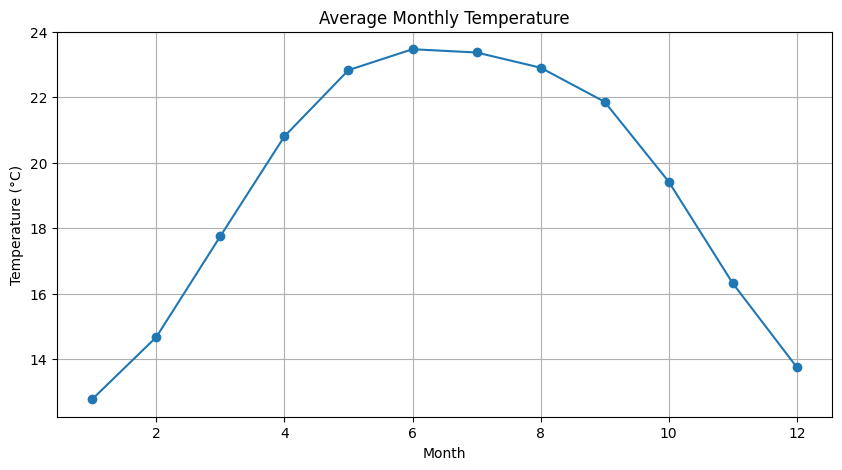

In [10]:
import matplotlib.pyplot as plt

monthly_temp = weather_df.groupby("Month")["Temperature_C"].mean()

plt.figure(figsize=(10,5))
plt.plot(monthly_temp.index, monthly_temp.values, marker='o')
plt.title("Average Monthly Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

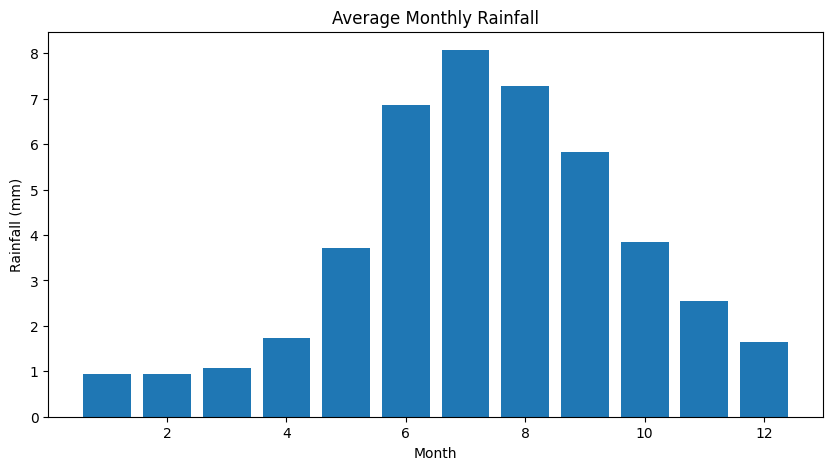

In [11]:
monthly_rain = weather_df.groupby("Month")["Rainfall_mm"].mean()

plt.figure(figsize=(10,5))
plt.bar(monthly_rain.index, monthly_rain.values)
plt.title("Average Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.show()

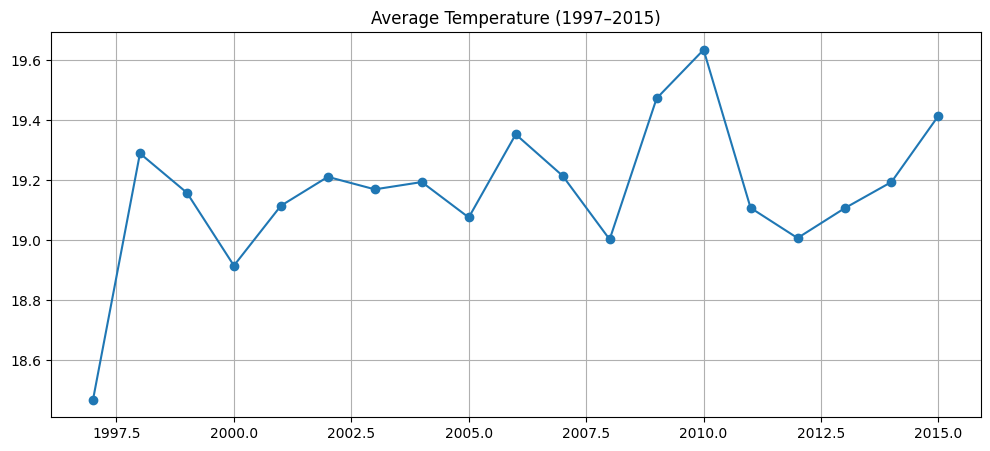

In [12]:
year_temp = weather_df.groupby("Year")["Temperature_C"].mean()

plt.figure(figsize=(12,5))
plt.plot(year_temp.index, year_temp.values, marker='o')
plt.title("Average Temperature (1997–2015)")
plt.grid(True)
plt.show()

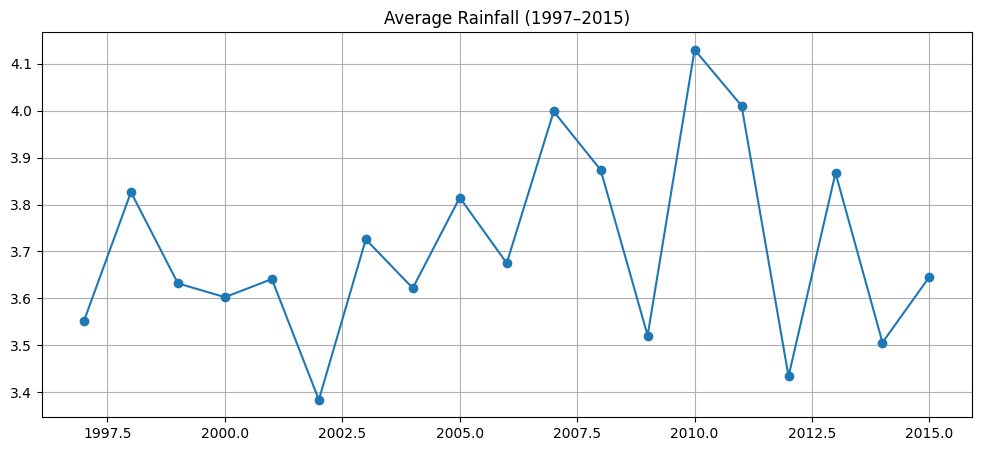

In [13]:
year_rain = weather_df.groupby("Year")["Rainfall_mm"].mean()

plt.figure(figsize=(12,5))
plt.plot(year_rain.index, year_rain.values, marker='o')
plt.title("Average Rainfall (1997–2015)")
plt.grid(True)
plt.show()

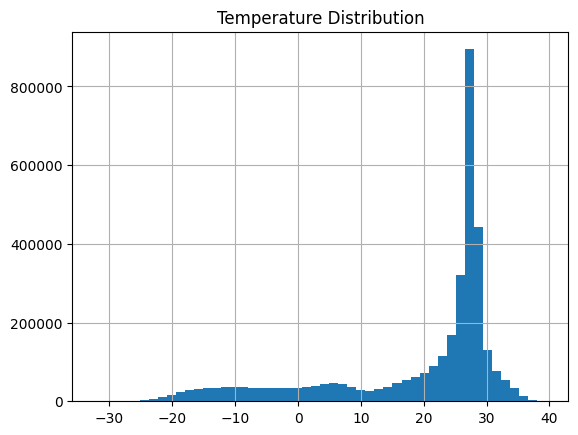

In [14]:
weather_df["Temperature_C"].hist(bins=50)
plt.title("Temperature Distribution")
plt.show()

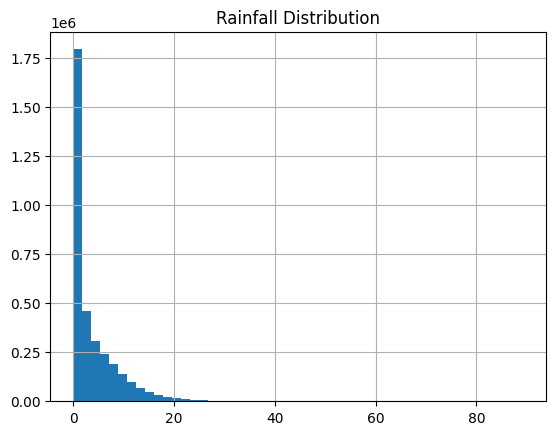

In [15]:
weather_df["Rainfall_mm"].hist(bins=50)
plt.title("Rainfall Distribution")
plt.show()

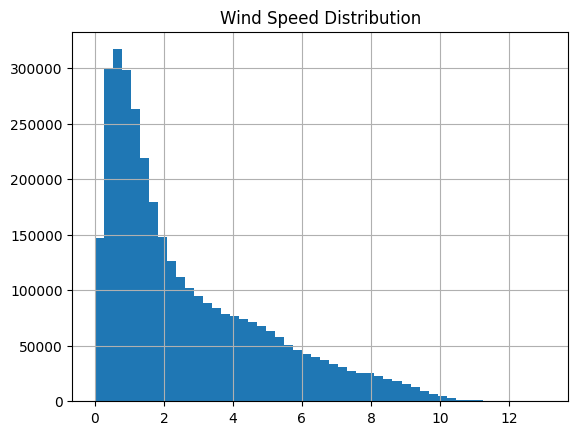

In [16]:
weather_df["Wind_Speed"].hist(bins=50)
plt.title("Wind Speed Distribution")
plt.show()

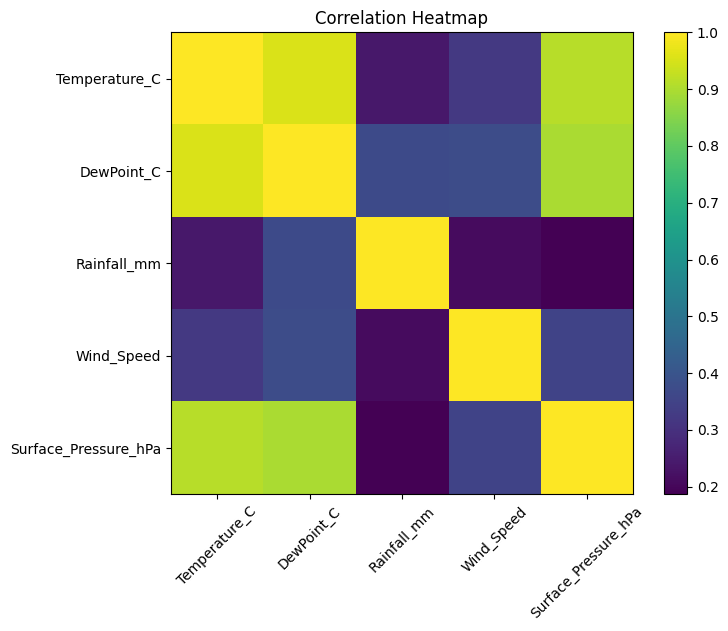

In [17]:
import matplotlib.pyplot as plt

corr = weather_df[
    [
        "Temperature_C",
        "DewPoint_C",
        "Rainfall_mm",
        "Wind_Speed",
        "Surface_Pressure_hPa"
    ]
].corr()

plt.figure(figsize=(8,6))
plt.imshow(corr, interpolation="nearest")
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Heatmap")
plt.show()

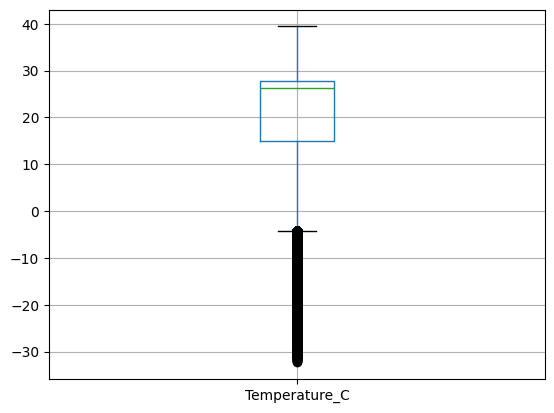

In [18]:
weather_df.boxplot(column="Temperature_C")
plt.show()

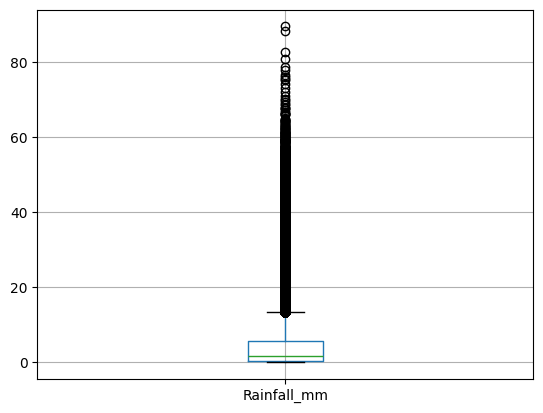

In [19]:
weather_df.boxplot(column="Rainfall_mm")
plt.show()

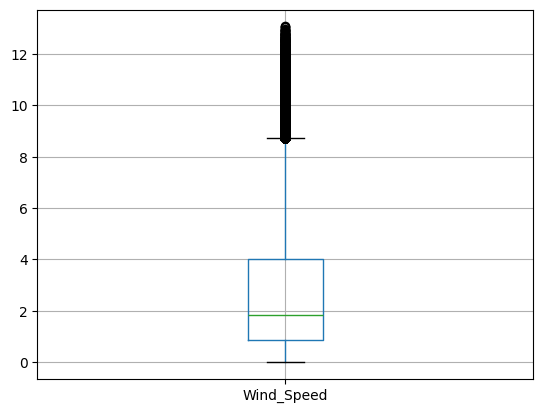

In [20]:
weather_df.boxplot(column="Wind_Speed")
plt.show()


In [21]:
weather_df.columns.tolist()

['Date',
 'Year',
 'Month',
 'Month_Name',
 'Latitude',
 'Longitude',
 'Temperature_C',
 'DewPoint_C',
 'Rainfall_mm',
 'Wind_Speed',
 'Surface_Pressure_hPa']